In [26]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [27]:
data_set = pd.read_csv('loan_data.csv')

In [28]:
data_set.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [29]:
data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

In [30]:
data_set.describe()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000


In [31]:
data_set.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

In [32]:
data_set['person_gender'].unique()

array(['female', 'male'], dtype=object)

(array([20159.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0., 24841.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

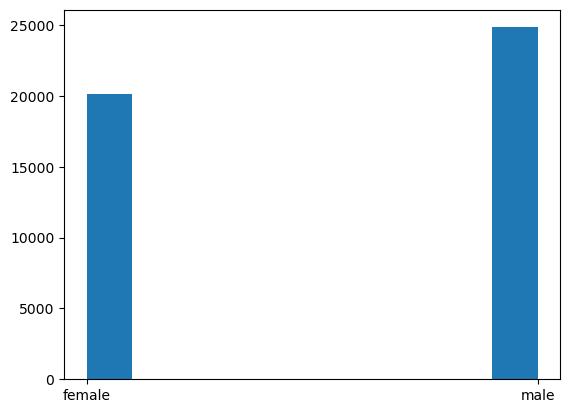

In [33]:
plt.hist(data_set['person_gender'])

In [34]:
data_set['person_education'].unique()

array(['Master', 'High School', 'Bachelor', 'Associate', 'Doctorate'],
      dtype=object)

(array([ 6980.,     0., 11972.,     0.,     0., 13399.,     0., 12028.,
            0.,   621.]),
 array([0. , 0.4, 0.8, 1.2, 1.6, 2. , 2.4, 2.8, 3.2, 3.6, 4. ]),
 <BarContainer object of 10 artists>)

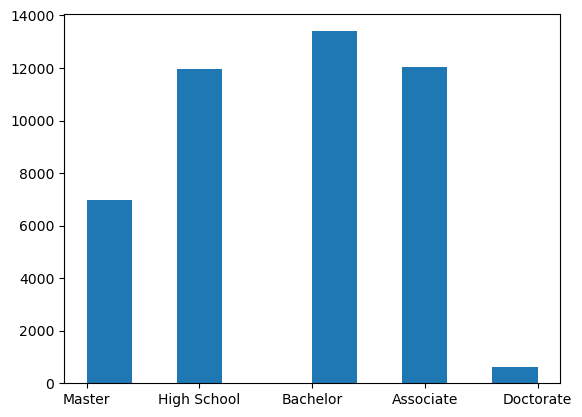

In [35]:
plt.hist(data_set['person_education'])

In [36]:
data_set['person_home_ownership'].unique()

array(['RENT', 'OWN', 'MORTGAGE', 'OTHER'], dtype=object)

(array([23443.,     0.,     0.,  2951.,     0.,     0., 18489.,     0.,
            0.,   117.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

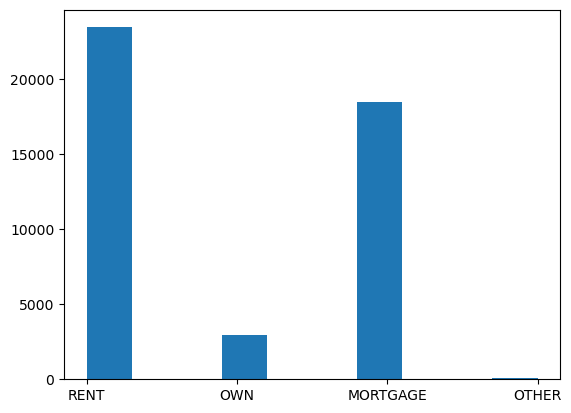

In [37]:
plt.hist(data_set['person_home_ownership'])

Splitting the dataset into dependent variable y and independent variable x

In [38]:
x = data_set.iloc[:,:-1].values
y = data_set.iloc[:,-1].values

Data Preprocessing

In [39]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
x[:,1]= le.fit_transform(x[:,1])
x[:,12]= le.fit_transform(x[:,12])

In [40]:
x

array([[22.0, 0, 'Master', ..., 3.0, 561, 0],
       [21.0, 0, 'High School', ..., 2.0, 504, 1],
       [25.0, 0, 'High School', ..., 3.0, 635, 0],
       ...,
       [33.0, 1, 'Associate', ..., 10.0, 668, 0],
       [29.0, 1, 'Bachelor', ..., 6.0, 604, 0],
       [24.0, 1, 'High School', ..., 3.0, 628, 0]], dtype=object)

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct = ColumnTransformer(transformers=[('encoder',OneHotEncoder(),[2,5,7])],remainder='passthrough')
x = ct.fit_transform(x)

In [42]:
x

array([[0.0, 0.0, 0.0, ..., 3.0, 561, 0],
       [0.0, 0.0, 0.0, ..., 2.0, 504, 1],
       [0.0, 0.0, 0.0, ..., 3.0, 635, 0],
       ...,
       [1.0, 0.0, 0.0, ..., 10.0, 668, 0],
       [0.0, 1.0, 0.0, ..., 6.0, 604, 0],
       [0.0, 0.0, 0.0, ..., 3.0, 628, 0]], dtype=object)

In [43]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2)

Feature Scalling

In [44]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

Classification Models

In [45]:
def Machine_Learning_models(x_train,x_test,y_train,y_test):
    models ={
        'Logistic Regression':LogisticRegression(),
        'K-Nearest Neighbors':KNeighborsClassifier(n_neighbors=10, metric='minkowski',p=2),
        'Kernel SVM':SVC(kernel='rbf'),
        'Naive Bayes':GaussianNB(),
        'Random Forest':RandomForestClassifier(n_estimators=200,criterion='entropy')

    }
    results = []
    for name, model in models.items():
        model.fit(x_train,y_train)
        y_pred = model.predict(x_test)
        test_acc = accuracy_score(y_test,y_pred)
        results.append({
            'Model': name,
            'Test Accuracy': test_acc
        })
    models_results = pd.DataFrame(results)
    display(models_results) 

Artificial Neuron Network

In [46]:
ann = tf.keras.models.Sequential()
ann.add(tf.keras.layers.Dense(units=15,activation='tanh'))
ann.add(tf.keras.layers.Dense(units=15,activation='tanh'))
#ann.add(tf.keras.layers.Dense(units=15,activation='relu'))
ann.add(tf.keras.layers.Dense(units=1,activation='sigmoid'))

In [47]:
ann.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [48]:
with tf.device('/CPU:0'):
    ann.fit(x_train,y_train,batch_size=32,epochs=100)

Epoch 1/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8028 - loss: 0.3990
Epoch 2/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8950 - loss: 0.2268
Epoch 3/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8976 - loss: 0.2195
Epoch 4/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9044 - loss: 0.2103
Epoch 5/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9097 - loss: 0.2031
Epoch 6/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9108 - loss: 0.1992
Epoch 7/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9086 - loss: 0.2016
Epoch 8/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9121 - loss: 0.1940
Epoch 9/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9150 - loss: 0.1900
Epoch 10/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9118 - loss: 0.1947
Epoch 11/100
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9125 - loss: 0.1895
Epoch 12/100
1125/1

In [49]:
y_pred1 = ann.predict(x_test)
y_pred1 = (y_pred1>0.5)

282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Results Comparison

ANN

In [50]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred1)

0.9195555555555556

Machine Learning Models

In [51]:
Machine_Learning_models(x_train,x_test,y_train,y_test)

,Model,Test Accuracy
0,Logistic Regression,0.900889
1,K-Nearest Neighbors,0.893222
2,Kernel SVM,0.918333
3,Naive Bayes,0.749111
4,Random Forest,0.929778
